# Complex Fourier Transform

## Complex numbers
Although complex numbers are fundamentally disconnected from our reality, they can be used to solve  science  and  engineering  problems  in  two  ways:
1. As parameters  from  a  real  world problem than can be substituted into a complex form.
2. As complex numbers that can be mathematically equivalent to the physical problem.

This  second approach leads to the complex Fourier Transform, a more sophisticated version of the real Fourier Transform.

## Review of Real DFT
We  defined  the  real  version  of  the  Discrete  Fourier  Transform according to the equations:

$$\mathbf{Re}X[k] = \sum^{N-1}_{n=0}x[n]\cos{(2\pi kn/N)}$$
$$\mathbf{Im}X[k] = -\sum^{N-1}_{n=0}x[n]\sin{(2\pi kn/N)}$$ 

where $0\leq k \leq N/2$

By introducing the normalization factor $2/N$, which comes from $Re\bar{X}[k]$ and $Im\bar{X}[k]$, we can write:
$$\mathbf{Re}X[k] = \frac{2}{N}\sum^{N-1}_{n=0}x[n]\cos{(2\pi kn/N)}$$
$$\mathbf{Im}X[k] =  -\frac{2}{N}\sum^{N-1}_{n=0}x[n]\sin{(2\pi kn/N)}$$ 

The amplitudes of the cosine waves are contained in $Re X[k]$, while the  amplitudes  of  the  sine  waves  are  contained in $ImX[k]$. These equations operate by correlating the respective cosine or sine wave with the time domain signal. In spite of using the names: real part and imaginary part, there are no complex numbers in these equations.

Even though  the  real  DFT  uses  only  real  numbers,  substitution  allows  the frequency domain to be represented using complex numbers.  As suggested by the  names  of  the  arrays. In other words, we  place  a $j$  with  each  value  in  the  imaginary  part,  and  add  the  result  to  the real  part. However, do not make the  mistake of thinking that this is the **"complex DFT"**. This is nothing more than the real DFT with complex substitution.

While  the  real  DFT  is  adequate  for  many  applications  in  science  and engineering, it is mathematically awkward in three respects:
1. Only takes advantage of complex numbers through the use of substitution, therefore complex numbers don't have a meaning here.
2. Poor handling of the negative frequency portion of the spectrum.
3. $Re X[0]$ and $Re X[N/2]$ need special handling.

## Euler's Refresher
We can use Euler's formula to express the relationship between the trigonometric functions and the complex exponential function as:

$$e^{jx}=\cos{(x)}+j\sin{(x)}$$

Using this formula, we can express sine and cosines as follows:

$$e^{-jx}=\cos{(-x)}+j\sin{(-x)}$$

Since cosine is an even and sine an odd function we can get:
$$e^{-jx}=\cos{(x)}-j\sin{(x)}$$

If we add $e^{jx}$ and $e^{-jx}$ we can get an expression for cosine as:
$$\cos(x) = \frac{e^{jx}+e^{-jx}}{2}$$

If we subtract $e^{jx}$ and $e^{-jx}$ we can get an expression for sine as:
$$\sin(x) = \frac{e^{jx}-e^{-jx}}{2j}$$

Rewriting for $x=\omega t$
$$\cos(\omega t) =\frac{1}{2} e^{j\omega t}+\frac{1}{2} e^{-j\omega t}$$
$$\sin(\omega t) =\frac{1}{2j}e^{j\omega t}-\frac{1}{2j}e^{-j\omega t}$$

With Euler's formula we see that the sum of exponential contains a positive frequency $\omega$ and a negative frequency $-\omega$. 

# Complex DFT

The Complex Discrete Fourier Transform is defined as:

$$X[k] = \frac{1}{N}\sum\limits^{N-1}_{n=0}{x[n]e^{-j\frac{2\pi k n}{N}}} $$

Where $X[k]$ has $N-1$ points.

By using Euler's formula we can get a rectangular form for the Complex DFT:

$$X[k] = \frac{1}{N}\sum\limits^{N-1}_{n=0}{x[n]\left[\cos{\left(\frac{2\pi k n}{N}\right)} -j\sin{\left(\frac{2\pi k n}{N}\right)} \right]} $$

## Differences between Real DFT and Complex DFT
1. Real DFT converts a real time domain signal, $x[n]$ into two real frequency domain signals $Re X[k]$ and $Im X[k]$. In Complex DFT, $x[n]$ and $X[k]$ are arrays of complex numbers.


2. Real DFT uses only positive frequencies (k goes from 0 to N/2). Complex DFT uses positive and negative frequencies (k goes from 0 to N-1, positive frequencies go from 0 to N/2 and negative from N/2 to N-1).


3. Real DFT adds $j$ to the sine wave allowing the frequency spectrum to be represented by complex numbers. To convert back to sine and cosine waves we drop the $j$ and sum terms. This is mathematically incorrect!


4. Scaling factors of two is not needed in Complex DFT, since this is dealt by the positive and negative frequency nature of the transformation.


5. Complex DFT doesn't require special handling of $Re X[0]$ and $Re X[N/2]$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

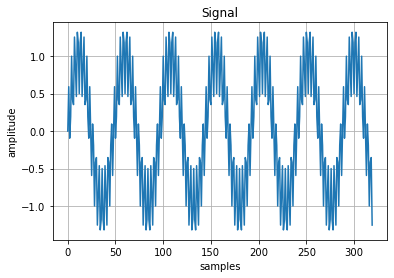

In [2]:
file = {'x':'Signals/InputSignal_f32_1kHz_15kHz.dat'}

x = np.loadtxt(file['x'])
N,M = x.shape
x = x.reshape(N*M, 1)

plt.plot(x)
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.title('Signal')
plt.grid('on')
plt.show()

## Implementation of the Complex Fourier Transform
In this part you will create a function called `complex_dft` which will perform the calculation of the Complex Fouier Transform described above, you have to take special care of your numpy arrays because they will hold complex values. The function `frequency_domain` is the same developed in the DFT notebook.

In [3]:
def complex_dft(x):
    """
    Function that calculates the Complex DFT of an input signal.
    
    Parameters: 
    signal (numpy array): Array of numbers representing the input signal.

    Returns: 
    complex numpy array: complex DFT of input signal of type imaginary.
    """

    N = x.shape[0]
    
    ### BEGIN SOLUTION
    X = np.zeros((N,1), dtype=complex)
    for k in range(N):
        for n in range(N):
            X[k] = X[k] + x[n]*np.exp(-1j*2*np.pi*k*n/N)
    X = X/N
    ### END SOLUTION
    return X

  
    
def frequency_domain(x, style='fraction', **kwargs):
    """ 
    Function that calculates the frequency domain independent variable.

    Parameters: 
    x (numpy array): Array of numbers representing the input signal inthe Fourier domain
    to  obtain the frequency independent variable.
    style (string): String value that selects between frequency domain's 
    independent variable.
        'samples' returns number of samples between 0 to N/2
        'fraction' returns a fraction of the sampling rate between 0 to 0.5
        'natural' returns the natural frequency between 0 and pi.
        'analog' returns analog frequency between 0 and fsamp/2
    fsamp (float): Float value representing the sampling frequency. 
        (Only used for 'analog' style).

    Returns: 
    numpy array: Returns frequency domain's independent variable.

        """
    N = x.shape[0]
    t = np.arange(N)
    
    ### BEGIN SOLUTION
       
    if(style=='fraction'):
        return t/(2*(N-1))
    elif(style=='natural'):
        return np.pi*(t/(2*(N-1)))
    elif(style=='analog'):
        return kwargs['fsamp']*(t/(2*(N-1)))
    elif(style=='samples'):
        return t
    else:
        return t
    
    ### END SOLUTION

### Test your Implementation
You can test your implementation and compare it with SciPy, if there is any mismatch try to correct your code.

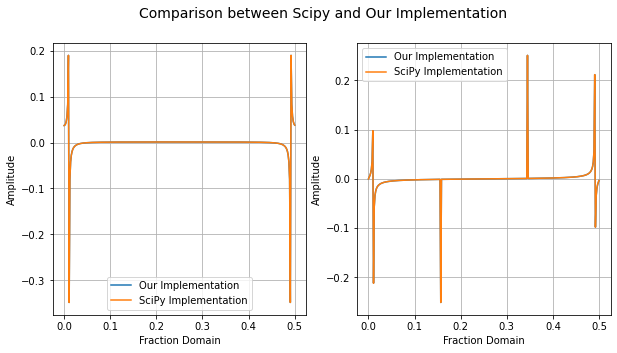

In [4]:
from scipy.fftpack import fft
#SciPy Calculations
y =fft(x.flatten())
N = y.shape[0]
rey = (np.real(y)).reshape(-1,1)/N #ScipPy does not normalize
imy = (np.imag(y)).reshape(-1,1)/N #ScipPy does not normalize

#Our Calculation
X = complex_dft(x)
f = frequency_domain(X, style='fraction')

plt.rcParams['figure.figsize'] = (10,5)
plt.suptitle("Comparison between Scipy and Our Implementation", fontsize=14)

plt.subplot(1,2,1)
plt.plot(f, np.real(X), label='Our Implementation')
plt.plot(f, rey, label='SciPy Implementation')
plt.xlabel('Fraction Domain')
plt.ylabel('Amplitude')
plt.legend()
plt.grid('on');

plt.subplot(1,2,2)
plt.plot(f, np.imag(X), label='Our Implementation')
plt.plot(f, imy, label='SciPy Implementation')
plt.xlabel('Fraction Domain')
plt.ylabel('Amplitude')
plt.legend()
plt.grid('on')
plt.show()

assert np.isclose(np.real(X), rey).all()
assert np.isclose(np.imag(X), imy).all()

# Complex IDFT

The Complex Inverse Discrete Fourier Transform is defined as:

$$x[n] = \sum\limits^{N-1}_{k=0}{X[k]e^{j\frac{2\pi k n}{N}}} $$

Where $x[n]$ has $N-1$ points.

By using Euler's formula we can get a rectangular form for the Complex IDFT:

$$x[n] = \sum\limits^{N-1}_{k=0}{\left(Re X[k]+j ImX[k] \right)e^{j\frac{2\pi k n}{N}}} $$
$$ = \sum\limits^{N-1}_{k=0}{Re X[k] e^{j\frac{2\pi k n}{N}}} + \sum\limits^{N-1}_{k=0}{j Im X[k] e^{j\frac{2\pi k n}{N}}} $$

with:
$$e^{j\frac{2\pi k n}{N}} = \left[\cos{\left(\frac{2\pi k n}{N}\right)} +j\sin{\left(\frac{2\pi k n}{N}\right)} \right]$$

therefore:
$$x[n] = \sum\limits^{N-1}_{k=0}{Re X[k] \left[\cos{\left(\frac{2\pi k n}{N}\right)} +j\sin{\left(\frac{2\pi k n}{N}\right)} \right]} + \sum\limits^{N-1}_{k=0}{Im X[k] \left[-\sin{\left(\frac{2\pi k n}{N}\right)} +j\cos{\left(\frac{2\pi k n}{N}\right)} \right]} $$


<br>
In words, each value in the real part of the frequency domain contributes a real cosine wave and an imaginary sine wave to the time domain.  Likewise, each value  in  the  imaginary  part  of  the  frequency  domain  contributes  a  real  sine wave and an imaginary cosine wave.  The time domain is found by adding all these real and imaginary sinusoids.  The important concept is that each value in  the  frequency  domain  produces  both  a  real  sinusoid  and  an  imaginary sinusoid in the time domain.

## Implement the Inverse Complex FourierTransform
Now you will implement a function called `complex_idft` which performs the Inverse Fourier Transform on a frequency signal using the equation explained above.

In [5]:
def complex_idft(X):
    """
    Function that calculates the Complex IDFT of an input signal.

    Returns: 
    complex numpy array: complex IDFT of input signal of type imaginary.
    """
    N = X.shape[0]
    
    ### BEGIN SOLUTION
    x = np.zeros((N,1), dtype=complex)
    for n in range(N):
        for k in range(N):
            x[n] = x[n] + X[k]*np.exp(1j*2*np.pi*k*n/N)
    ### END SOLUTION
    return x

### Test your ComplexFourierTransform Class
You can test your implementation and compare it with the original signal, if there is any mismatch try to correct your code. Try to understand both the real and imaginary signals that the Complex IDFT generates.

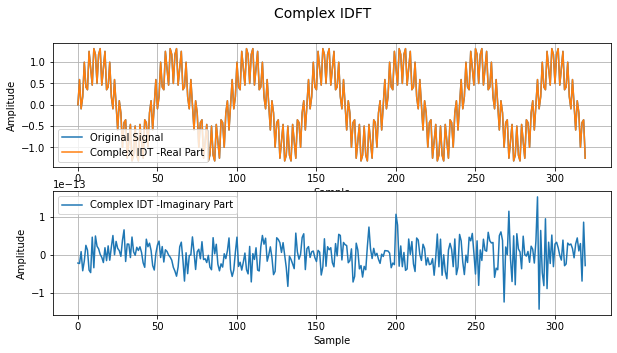

In [6]:
#Our Calculation
X = complex_dft(x)
x_idft = complex_idft(X)
f = frequency_domain(X, style='fraction')

plt.suptitle("Complex IDFT", fontsize=14)

plt.subplot(2,1,1)
plt.plot(x, label='Original Signal')
plt.plot(np.real(x_idft), label='Complex IDT -Real Part')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.grid('on')

plt.subplot(2,1,2)
plt.plot(np.imag(x_idft), label='Complex IDT -Imaginary Part')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.grid('on')

plt.show()

# Check if implementation reproduces original signal until certain threshold
epsilon = 10**-13
assert np.abs(np.sum(np.real(x_idft)-x))<=epsilon

## A Pure Real Signal
Previously we developed our `mean` and `variance` functions, but in this case we will use the ones provided by NumPy to calculate both metrics.

In [7]:
X = complex_dft(x)
x_idft = complex_idft(X)

# Calculate the mean values of the real and imaginary parts of the Inverse Complex Fourier Transform
# Name them mean_real_idft and mean_imag_idft respectively.
### BEGIN SOLUTION
mean_real_idft = np.mean(np.real(x_idft))
mean_imag_idft = np.mean(np.imag(x_idft))
### END SOLUTION

# Calculate the variance values of the real and imaginary parts of the Inverse Complex Fourier Transform
# Name them var_real_idft and var_imag_idft respectively.
### BEGIN SOLUTION
var_real_idft = np.var(np.real(x_idft))
var_imag_idft = np.var(np.imag(x_idft))
### END SOLUTION

In [8]:
print('Mean of the real IDFT signal = {:.3f}'.format(mean_real_idft))
print('Mean of the imaginary IDFT signal = {:.3f}'.format(mean_imag_idft))

print('\nVariance of the real IDFT signal = {:.3f}'.format(var_real_idft))
print('Variance of the imaginary IDFT signal = {:.3f}'.format(var_imag_idft))


with open('metrics.pkl', 'rb') as file:
    metrics = pickle.load(file)
    
    
assert np.isclose(mean_real_idft, metrics['mean_real_idft'], atol=0.01)
assert np.isclose(mean_imag_idft, metrics['mean_imag_idft'], atol=0.01)
assert np.isclose(var_real_idft, metrics['var_real_idft'], atol=0.001)
assert np.isclose(var_imag_idft, metrics['var_imag_idft'], atol=0.001)

Mean of the real IDFT signal = 0.037
Mean of the imaginary IDFT signal = 0.000

Variance of the real IDFT signal = 0.618
Variance of the imaginary IDFT signal = 0.000


From the previous metrics you can see that the recovered signal only consist of a real part in the IDFT, so by using the mean and variance we can be assured to say that our signal is a *pure real signal*.

#### References:

* https://www.dspguide.com/ch31.htm